# Detecting illicit Bitcoin transactions on the Elliptic graph

BT4012 Kaggle competition, student number e1113794. Every transaction in the test period (time steps 36-49) gets a probability of being illicit; the score is ROC AUC.

This notebook rebuilds, from the four Kaggle files in `data/raw/`, the two submissions I selected for the final leaderboard. Everything is seeded, so a rerun reproduces both CSVs to about 1e-16 (LightGBM 4.5.0, scikit-learn 1.5.2): the CSVs are written to `submissions/` (created if missing), and if a file of the same name is already there, the largest difference from it is printed (about 1e-16 against the files I submitted). A full run takes about 12 minutes.

| submission | what it is | public AUC |
| --- | --- | --- |
| `selftrain_wide_3649_stepquantile.csv` (top pick, **private AUC 0.95986**) | model A, plus a separate model and a time-step shift for steps 43-49, plus three rounds of self-training (section 8) | 0.95832 |
| `robust_struct_pu_refined.csv` (second pick) | model A: LightGBM + positive-unlabelled model + graph smoothing (section 7) | 0.95031 |

Contents: 1 data checks, 2 what the data look like, 3 feature selection, 4 graph features, 5 the models, 6 validation, 7 model A and its CSV, 8 model B (top pick) and its CSV, 9 evidence from the leaderboard.

In [1]:
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp
import sklearn
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy.sparse.csgraph import connected_components
from scipy.special import expit
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

DATA = Path("data/raw")             # train.csv, test.csv, txs_edgelist.csv, sample_submission.csv
SUBMISSIONS = Path("submissions")   # the two final CSVs are written here
SUBMISSIONS.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 12)
warnings.filterwarnings("ignore", message=".*encountered in matmul")  # spurious with numpy's macOS BLAS
print(f"lightgbm {lgb.__version__}, scikit-learn {sklearn.__version__}, pandas {pd.__version__}, numpy {np.__version__}, networkx {nx.__version__}")

# one colour per class, used the same way in every chart
SURFACE, INK_2, MUTED, AXIS = "#fcfcfb", "#52514e", "#898781", "#c3c2b7"
COLORS = {"illicit": "#eb6834", "licit": "#2a78d6", "unknown": "#c3c2b7", "test": "#1baf7a"}
ACCENT = "#4a3aa7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": "#e1e0d9", "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "semibold",
    "legend.frameon": False,
})

lightgbm 4.5.0, scikit-learn 1.5.2, pandas 2.2.3, numpy 2.1.3, networkx 3.6.1


## 1. Load and check

`train.csv` (steps 1-35, with labels), `test.csv` (steps 36-49, no labels), `txs_edgelist.csv` (directed edges: an output of `txId1` is spent as an input of `txId2`) and `sample_submission.csv`. The submission is keyed on `test.csv`'s own `index` column, not on `txId`.

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
edges = pd.read_csv(DATA / "txs_edgelist.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")

FEATURES = [c for c in train.columns if c.startswith("feat_")]   # feat_1..93 are local, feat_94..165 aggregated over neighbours

for name, df in [("train", train), ("test", test), ("edges", edges), ("sample_submission", sample)]:
    print(f"{name:<18} {df.shape[0]:>8,} rows {df.shape[1]:>5} columns")

labelled = train[train.label.notna()]
dupes = labelled[labelled.duplicated(subset=FEATURES, keep=False)]
checks = pd.Series({
    "missing values in train (excluding label)": train.drop(columns="label").isna().sum().sum(),
    "missing values in test": test.isna().sum().sum(),
    "duplicate txIds within train / test": f"{train.txId.duplicated().sum()} / {test.txId.duplicated().sum()}",
    "txIds in both train and test": len(set(train.txId) & set(test.txId)),
    "train rows repeating another row's features": train.duplicated(subset=FEATURES).sum(),
    "repeated labelled rows that disagree on the label": dupes.groupby(FEATURES).label.nunique().gt(1).sum(),
    "sample_submission index matches test index": sample["index"].equals(test["index"]),
})
checks.to_frame("value")

train               141,772 rows   168 columns
test                 15,329 rows   168 columns
edges               234,355 rows     2 columns
sample_submission    15,329 rows     2 columns


,value
missing values in train (excluding label),0
missing values in test,0
duplicate txIds within train / test,0 / 0
txIds in both train and test,0
train rows repeating another row's features,31
repeated labelled rows that disagree on the label,0
sample_submission index matches test index,True


## 2. What the data look like

The edge list covers more transactions than the two files: ids without a row are transactions whose features and labels were withheld ("edge list only"). I link the graph to the files, and count the labels.

In [3]:
step_of = pd.concat([train.set_index("txId").time_step, test.set_index("txId").time_step])
graph_ids = pd.unique(edges[["txId1", "txId2"]].to_numpy().ravel())
ghosts = np.setdiff1d(graph_ids, step_of.index)       # in the edge list, but in neither file

print(f"transactions in the edge list       {len(graph_ids):>8,}")
print(f"  with a row in train or test       {np.isin(graph_ids, step_of.index).sum():>8,}")
print(f"  in neither file                   {len(ghosts):>8,}")
print(f"rows in train/test without any edge {len(np.setdiff1d(step_of.index, graph_ids)):>8,}")

G = nx.Graph()
G.add_edges_from(edges.itertuples(index=False, name=None))
components = [list(c) for c in nx.connected_components(G)]
component_steps = [step_of.reindex(c).dropna().unique() for c in components]
print("\nconnected components:", len(components))
print("components spanning more than one time step:", sum(len(s) != 1 for s in component_steps))

step_by_tx = {tx: int(s[0]) for c, s in zip(components, component_steps) for tx in c}
ghost_step = pd.Series({tx: step_by_tx[tx] for tx in ghosts})
print("time steps of the transactions missing from both files:", ghost_step.min(), "to", ghost_step.max())

transactions in the edge list        203,769
  with a row in train or test        157,101
  in neither file                     46,668
rows in train/test without any edge        0



connected components: 49
components spanning more than one time step: 0
time steps of the transactions missing from both files: 36 to 49


In [4]:
status = train.label.map({0: "licit", 1: "illicit"}).fillna("unknown")
counts = status.value_counts().reindex(["licit", "illicit", "unknown"])
n_labelled, n_unknown = len(labelled), len(train) - len(labelled)
print(f"illicit share among labelled rows: {labelled.label.mean():.1%}")
print(f"train: {n_unknown / n_labelled:.2f} unlabelled rows per labelled row;  test period: {len(ghosts) / len(test):.2f} edge-list-only transactions per test row")

# Elliptic's published totals are 4,545 illicit and 42,019 licit labelled transactions; the rest is in test
test_illicit = 4_545 - int(labelled.label.sum())
test_licit = 42_019 - int((labelled.label == 0).sum())
print(f"implied test labels: {test_illicit:,} illicit + {test_licit:,} licit = {test_illicit + test_licit:,} rows (test has {len(test):,}), "
      f"illicit share {test_illicit / len(test):.1%}")
pd.DataFrame({"rows": counts, "share of train": (counts / len(train)).map("{:.1%}".format)})

illicit share among labelled rows: 11.7%
train: 3.54 unlabelled rows per labelled row;  test period: 3.04 edge-list-only transactions per test row
implied test labels: 901 illicit + 14,428 licit = 15,329 rows (test has 15,329), illicit share 5.9%


,rows,share of train
label,,
licit,27591,19.5%
illicit,3644,2.6%
unknown,110537,78.0%


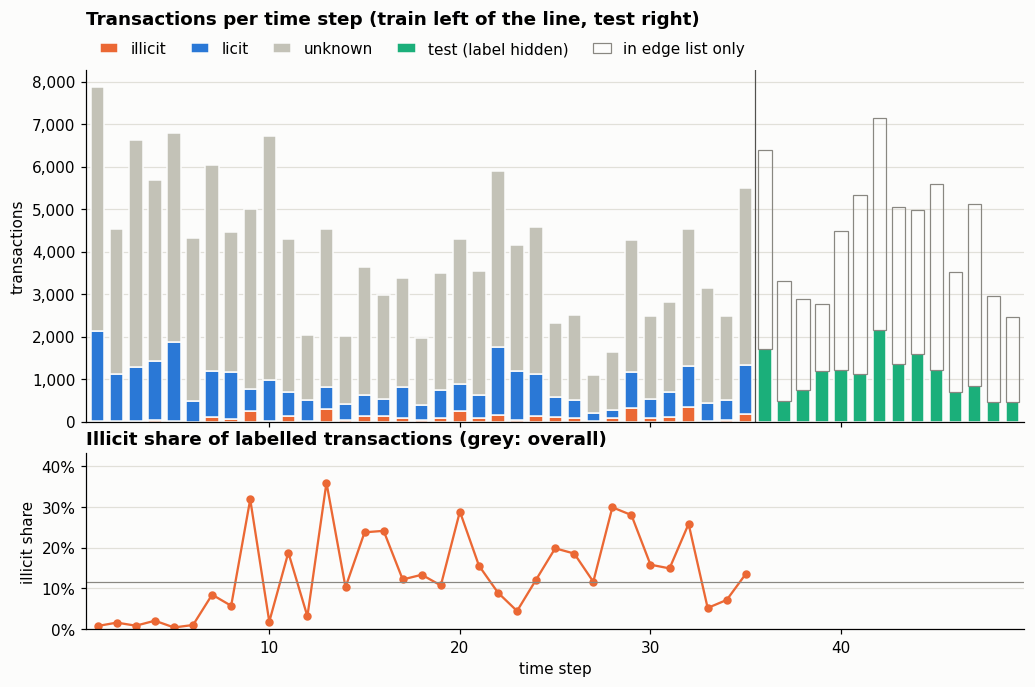

In [5]:
per_step = pd.crosstab(train.time_step, status)[["illicit", "licit", "unknown"]]
test_per_step = test.time_step.value_counts().sort_index()
ghost_per_step = ghost_step.value_counts().sort_index()
rate = labelled.groupby("time_step").label.mean()

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6.6), sharex=True, gridspec_kw={"height_ratios": [2, 1], "hspace": 0.12})
bar = dict(width=0.7, edgecolor=SURFACE, linewidth=1)
bottom = np.zeros(len(per_step))
for cls in ["illicit", "licit", "unknown"]:
    ax.bar(per_step.index, per_step[cls], bottom=bottom, color=COLORS[cls], label=cls, **bar)
    bottom += per_step[cls].to_numpy()
ax.bar(test_per_step.index, test_per_step, color=COLORS["test"], label="test (label hidden)", **bar)
ax.bar(ghost_per_step.index, ghost_per_step, bottom=test_per_step[ghost_per_step.index], width=0.7,
       facecolor="none", edgecolor=MUTED, linewidth=0.8, label="in edge list only")
ax.axvline(35.5, color=INK_2, linewidth=0.8)
ax.set(xlim=(0.4, 49.6), ylabel="transactions")
ax.set_title("Transactions per time step (train left of the line, test right)", pad=30)
ax.legend(ncols=5, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1.2, columnspacing=1.6)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax2.plot(rate.index, rate, color=COLORS["illicit"], marker="o", markersize=4.5)
ax2.axhline(labelled.label.mean(), color=MUTED, linewidth=0.8)
ax2.set(xlabel="time step", ylabel="illicit share", ylim=(0, rate.max() * 1.2))
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set_title("Illicit share of labelled transactions (grey: overall)")
plt.show()

The edges only join transactions of the same time step, and the graph is acyclic. Two consequences for modelling: no test transaction has a labelled neighbour (so neighbour-*label* features and label propagation are useless), and about half of a test transaction's neighbours are edge-list-only ids. The next cell shows how the neighbours of each type are distributed.

In [6]:
D = nx.DiGraph(edges.itertuples(index=False, name=None))
print("directed acyclic:", nx.is_directed_acyclic_graph(D), "  self-loops:", nx.number_of_selfloops(D), "  duplicate edges:", edges.duplicated().sum())

degree = pd.DataFrame({"in": edges.txId2.value_counts(), "out": edges.txId1.value_counts()}).fillna(0).astype(int)
degree["total"] = degree["in"] + degree["out"]

node_type = pd.concat([pd.Series(status.to_numpy(), index=train.txId), pd.Series("test", index=test.txId), pd.Series("edge list only", index=ghosts)])
both_ways = pd.concat([
    edges.set_axis(["node", "neighbour"], axis=1),
    edges[["txId2", "txId1"]].set_axis(["node", "neighbour"], axis=1),
], ignore_index=True)

kinds = ["illicit", "licit", "unknown", "test", "edge list only"]
mix = pd.crosstab(both_ways.node.map(node_type), both_ways.neighbour.map(node_type), normalize="index").loc[["illicit", "licit", "unknown", "test"], kinds]
labelled_neighbours = mix.loc[["illicit", "licit"], ["illicit", "licit"]]
print("illicit share among labelled neighbours (rows: type of the transaction):")
print((labelled_neighbours["illicit"] / labelled_neighbours.sum(axis=1)).map("{:.1%}".format).to_string(), "\n")
mix.round(3)

directed acyclic: True   self-loops: 0   duplicate edges: 0
illicit share among labelled neighbours (rows: type of the transaction):
node
illicit    57.4%
licit       2.8% 



neighbour,illicit,licit,unknown,test,edge list only
node,,,,,
illicit,0.234,0.174,0.592,0.000,0.000
licit,0.015,0.530,0.455,0.000,0.000
unknown,0.018,0.158,0.824,0.000,0.000
test,0.000,0.000,0.000,0.512,0.488


Illicit transactions sit next to illicit ones far more often than licit ones do, so neighbours carry signal that I can use on test through the *predictions* of the neighbours (the smoother in section 5), not through labels.

Six features rise almost linearly with the time step ("clock" features) and mostly fall outside the train range in test:

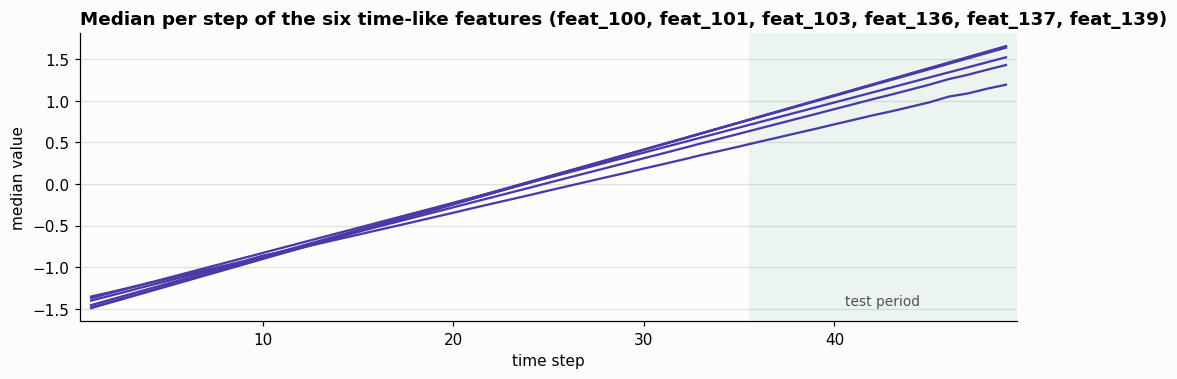

,Spearman with time_step
feat_101,0.998
feat_103,0.996
feat_136,0.994
feat_100,0.994
feat_139,0.962
feat_137,0.901
feat_2,0.602
feat_109,0.571


In [7]:
X = pd.concat([train[FEATURES], test[FEATURES]], ignore_index=True)
steps_all = pd.concat([train.time_step, test.time_step], ignore_index=True)
rho = X.corrwith(steps_all, method="spearman")
CLOCK = rho.index[rho.abs() > 0.8].tolist()
medians = X[CLOCK].groupby(steps_all).median()

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.axvspan(35.5, 49.6, color=COLORS["test"], alpha=0.08, linewidth=0)
ax.text(42.5, medians.to_numpy().min(), "test period", ha="center", va="bottom", color=INK_2, fontsize=9)
for feat in CLOCK:
    ax.plot(medians.index, medians[feat], color=ACCENT, linewidth=1.5)
ax.set(xlim=(0.4, 49.6), xlabel="time step", ylabel="median value")
ax.set_title(f"Median per step of the six time-like features ({', '.join(CLOCK)})")
plt.show()
rho.reindex(rho.abs().sort_values(ascending=False).index).head(8).round(3).to_frame("Spearman with time_step")

## 3. Feature selection

165 anonymised features, 93 local (the transaction itself) and 72 aggregated (statistics over 1-hop neighbours). Four rules give the 97-feature set `SELECTED` that every model below uses:

1. **Drop near-duplicates:** one feature from each group of features with |r| > 0.99 (keep the lowest-numbered).
2. **Drop the 30 features that drift most** between licit training rows and the test rows (single-feature AUC of "licit train vs test"; test labels are never used, only test features).
3. **Never drop the surviving clock features.** Keeping them gave +0.008 in validation at k = 30 (trees can split by period); on the leaderboard dropping them cost 0.0003.
4. **Never drop the 5 strongest features** (chosen on train rows), otherwise the drift filter removes `feat_53` and `feat_55`.

In [8]:
with np.errstate(invalid="ignore"):
    corr = np.corrcoef(X.to_numpy(), rowvar=False)
upper = np.triu_indices(len(FEATURES), k=1)
pairs = pd.DataFrame({"a": np.array(FEATURES)[upper[0]], "b": np.array(FEATURES)[upper[1]], "r": corr[upper]})
twins = pairs[pairs.r.abs() > 0.99]
twin_groups = list(nx.connected_components(nx.Graph(twins[["a", "b"]].itertuples(index=False, name=None))))
print(f"pairs with |r| > 0.95: {(pairs.r.abs() > 0.95).sum()};  pairs with |r| > 0.99: {len(twins)}, in {len(twin_groups)} groups")

number = lambda feature: int(feature.split("_")[1])
duplicate_of = {}
for group in twin_groups:
    keep, *drop = sorted(group, key=number)
    duplicate_of.update(dict.fromkeys(drop, keep))

DEDUP = [f for f in FEATURES if f not in duplicate_of]
CLOCK_KEPT = [f for f in CLOCK if f in DEDUP]
NO_CLOCK = [f for f in DEDUP if f not in CLOCK_KEPT]
print(f"{len(duplicate_of)} near-duplicates removed, {len(DEDUP)} features left;  clock features that survive: {CLOCK_KEPT}")


def drift_score(reference, target, cols):
    """Per feature: 0 = same distribution in both sets, 1 = perfectly separable."""
    y = np.r_[np.zeros(len(reference)), np.ones(len(target))]
    stacked = pd.concat([reference[cols], target[cols]])
    return (stacked.apply(lambda col: roc_auc_score(y, col)) - 0.5).abs() * 2


def strongest(rows, cols, n):
    """The n features with the highest single-feature AUC on `rows`."""
    auc = rows[cols].apply(lambda col: roc_auc_score(rows.label, col))
    return np.maximum(auc, 1 - auc).nlargest(n).index.tolist()


def final_columns(train_rows, target_rows, k=30, protect=5):
    """Rules 2-4: drop the k most drifting features between licit `train_rows` and `target_rows`, sparing the clock and the strongest."""
    protected = strongest(train_rows, NO_CLOCK, protect)
    candidates = [c for c in NO_CLOCK if c not in protected]
    drift = drift_score(train_rows[train_rows.label == 0], target_rows, candidates)
    dropped = sorted(drift.nlargest(k).index, key=number)
    return [c for c in DEDUP if c not in dropped], dropped


SELECTED, DROPPED = final_columns(labelled, test)
auc = labelled[FEATURES].apply(lambda col: roc_auc_score(labelled.label, col))
strength = np.maximum(auc, 1 - auc)
print(f"\n{len(SELECTED)} features selected for the final model")
print(f"dropped for drift ({len(DROPPED)}):", ", ".join(DROPPED))
print("strong features (single-feature AUC above 0.78) among them:", [f for f in DROPPED if strength[f] > 0.78] or "none")

# validation windows used from here on: (last training step, first and last step scored); train on every labelled row up to the first
ALL_HORIZONS = [(10, 11, 24), (14, 15, 28), (17, 18, 31), (19, 20, 33), (21, 22, 35), (24, 25, 35), (27, 28, 35)]
overlap = {f"{lo}-{hi}": len(set(final_columns(labelled[labelled.time_step <= last], labelled[labelled.time_step.between(lo, hi)])[1]) & set(DROPPED))
           for last, lo, hi in ALL_HORIZONS}
print("\nsame features dropped when the filter is run on a validation window instead of test (out of 30):", overlap)

pairs with |r| > 0.95: 92;  pairs with |r| > 0.99: 42, in 30 groups
38 near-duplicates removed, 127 features left;  clock features that survive: ['feat_100', 'feat_136', 'feat_137', 'feat_139']



97 features selected for the final model
dropped for drift (30): feat_2, feat_3, feat_10, feat_23, feat_24, feat_42, feat_48, feat_54, feat_59, feat_61, feat_79, feat_83, feat_85, feat_89, feat_91, feat_94, feat_96, feat_106, feat_107, feat_109, feat_112, feat_113, feat_115, feat_142, feat_143, feat_144, feat_145, feat_148, feat_149, feat_151
strong features (single-feature AUC above 0.78) among them: ['feat_23', 'feat_89', 'feat_142']



same features dropped when the filter is run on a validation window instead of test (out of 30): {'11-24': 21, '15-28': 19, '18-31': 20, '20-33': 22, '22-35': 22, '25-35': 26, '28-35': 25}


Effect of the four rules, on three 14-step validation windows (15-28, 18-31, 22-35; each trained on all earlier labelled steps), mean AUC over all rows, two LightGBM seeds. *Recorded in the development notebook, not recomputed here.*

| feature set | 15-28 | 18-31 | 22-35 | mean | vs all 165 |
| --- | --- | --- | --- | --- | --- |
| all 165 features | 0.9602 | 0.9087 | 0.8927 | 0.9206 | 0 |
| drop near-duplicates | 0.9572 | 0.9111 | 0.8909 | 0.9197 | -0.0008 |
| + drop the 30 most drifting | 0.9649 | 0.9218 | 0.9092 | 0.9320 | +0.0114 |
| + keep the clock features | 0.9645 | 0.9309 | 0.9256 | 0.9403 | +0.0198 |
| + protect the 5 strongest (`SELECTED`) | 0.9651 | 0.9309 | 0.9256 | 0.9405 | +0.0200 |

The seed noise on the mean is about 0.004, so only the drift filter and the clock features are clear effects. Section 6 shows that most of this gain is one illicit pattern, and re-checks the choices on a score that removes it.

## 4. Graph features

Test transactions have no labelled neighbours, but their neighbourhood still says something. I add 11 features computed on the full edge list (including the edge-list-only ids):

- **Neighbour counts:** `nb_labelled` (neighbours that have a row in train-labelled or test), `nb_unknown` (neighbours without one: unlabelled train rows or edge-list-only ids) and `nb_unknown_share`. Test rows lose about half their neighbours to the missing ids, so this tells the model how much of a node's neighbourhood it cannot see.
- **Structure:** PageRank forward and reversed, k-core number, triangles, clustering coefficient, the longest directed path ending / starting at the node, and the number of nodes within 2 hops.

Hubs (11 or more neighbours) are 1.3% of the transactions but touch 28% of the edges; they are handled separately in the smoother.

In [9]:
HUB = 11  # a transaction with this many neighbours or more counts as a hub
edge_table = edges.assign(deg1=edges.txId1.map(degree.total), deg2=edges.txId2.map(degree.total))
print(f"transactions with {HUB}+ neighbours: {(degree.total >= HUB).mean():.1%}, "
      f"edges that touch one: {(np.maximum(edge_table.deg1, edge_table.deg2) >= HUB).mean():.1%}")

labelled_or_test = set(labelled.txId) | set(test.txId)
COUNT_COLS = ["nb_labelled", "nb_unknown", "nb_unknown_share"]


def neighbour_counts(rows):
    pairs = both_ways[both_ways.node.isin(rows.txId)]
    has_row = pairs.neighbour.isin(labelled_or_test)
    counts = pd.DataFrame({"nb_labelled": has_row.groupby(pairs.node.to_numpy()).sum(),
                           "nb_unknown": (~has_row).groupby(pairs.node.to_numpy()).sum()})
    counts["nb_unknown_share"] = counts.nb_unknown / (counts.nb_labelled + counts.nb_unknown)
    out = rows.join(counts, on="txId")
    out[["nb_labelled", "nb_unknown"]] = out[["nb_labelled", "nb_unknown"]].fillna(0)
    return out


labelled_counts, test_counts = neighbour_counts(labelled), neighbour_counts(test)


def pagerank(adjacency, alpha=0.85, iterations=50):
    """Power iteration; the mass of nodes with no outgoing edge is spread evenly."""
    n = adjacency.shape[0]
    out_degree = np.asarray(adjacency.sum(axis=1)).ravel()
    inverse = np.divide(1, out_degree, out=np.zeros(n), where=out_degree > 0)
    rank = np.full(n, 1 / n)
    for _ in range(iterations):
        rank = (1 - alpha) / n + alpha * (adjacency.T @ (rank * inverse) + rank[out_degree == 0].sum() / n)
    return rank


node_ids = pd.Index(sorted(G.nodes))
node_pos = pd.Series(np.arange(len(node_ids)), index=node_ids)
forward = sp.csr_matrix((np.ones(len(edges)), (node_pos.loc[edges.txId1], node_pos.loc[edges.txId2])), shape=(len(node_ids),) * 2)
undirected = ((forward + forward.T) > 0).astype(float).tocsr()

# along the directed graph, which is acyclic, longest path ending / starting at each node
longest_in, longest_out = dict.fromkeys(D, 0), dict.fromkeys(D, 0)
topological = list(nx.topological_sort(D))
for v in topological:
    for w in D.successors(v):
        longest_in[w] = max(longest_in[w], longest_in[v] + 1)
for v in reversed(topological):
    for w in D.successors(v):
        longest_out[v] = max(longest_out[v], longest_out[w] + 1)

structure = pd.DataFrame({
    "pr_fwd": pagerank(forward), "pr_rev": pagerank(forward.T.tocsr()),
    "kcore": pd.Series(nx.core_number(G)).reindex(node_ids), "tri": pd.Series(nx.triangles(G)).reindex(node_ids),
    "clust": pd.Series(nx.clustering(G)).reindex(node_ids),
    "longest_in": pd.Series(longest_in).reindex(node_ids), "longest_out": pd.Series(longest_out).reindex(node_ids),
    "reach2": np.asarray(((undirected @ undirected) > 0).sum(axis=1)).ravel(),
}, index=node_ids)
STRUCT_COLS = list(structure.columns)

labelled_struct, test_struct = labelled_counts.join(structure, on="txId"), test_counts.join(structure, on="txId")
structure.describe().loc[["mean", "50%", "max"]].round(3)

transactions with 11+ neighbours: 1.3%, edges that touch one: 28.3%


,pr_fwd,pr_rev,kcore,tri,clust,longest_in,longest_out,reach2
mean,0.0,0.000,1.376,0.127,0.014,21.919,20.853,22.049
50%,0.0,0.000,1.000,0.000,0.000,2.000,3.000,4.000
max,0.0,0.001,9.000,74.000,1.000,1248.000,1248.000,744.000


## 5. The models

Three pieces, shared by both submissions.

**Supervised model.** LightGBM (600 trees, learning rate 0.03, 31 leaves, column subsampling 0.5) trained on every labelled train row with the 108 columns `SELECTED + neighbour counts + structure`. I average the logits of 5 seeds. LightGBM was the best model family on the validation below (random forest, extra trees, XGBoost, logistic regression and rank blends of them did no better), and tuning its settings gave nothing further.

**Positive-unlabelled (PU) model.** A second LightGBM (3 seeds) that separates the known illicit rows from *all* unlabelled train rows, with the clock features removed. The unlabelled rows are 78% of train and are not used by the supervised model; the PU model learns what illicit rows look like against the general population, without the labelled licit rows' selection. Alone it is weaker (0.985 against 0.996 on validation) but it blends well: `logit = (1 - w) * supervised + w * PU`.

**Graph smoother.** Predictions are smoothed over the graph of the *scored* rows (a test row only sees other test rows): 10 rounds of propagation with restart (each round pulls a row 30% towards the mean logit of its neighbours, anchored to the original), over non-hub edges only, plus extra links between two scored rows that pay into the same small transaction; then a final pull of weight 0.15 towards the mean of its hub-free component (components of 3 or more rows).

In [10]:
PARAMS = dict(
    n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
    n_jobs=4, force_col_wise=True, verbose=-1,  # 4 threads was fastest on my laptop
)


def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def lgbm(seed):
    return lgb.LGBMClassifier(**PARAMS, random_state=seed)


def fit_logits(make_model, X_fit, y_fit, X_score, seeds):
    """Mean over seeds of the logit of the predicted probability."""
    return np.mean([logit(make_model(seed).fit(X_fit, y_fit).predict_proba(X_score)[:, 1]) for seed in seeds], axis=0)


unlabelled = train[train.label.isna()]


def fit_pu(rows, last, cols, score_rows, seeds):
    """Illicit rows against every unlabelled train row up to step `last`; returns the logit of 'looks illicit-like' for `score_rows`."""
    positives = rows[(rows.time_step <= last) & rows.label.eq(1)]
    pool = unlabelled[unlabelled.time_step <= last]
    X = pd.concat([positives[cols], pool[cols]])
    y = np.r_[np.ones(len(positives)), np.zeros(len(pool))]
    return fit_logits(lgbm, X, y, score_rows[cols], seeds)


def scored_graph(ids, hub=HUB):
    """What the smoother needs for one scored set: its edges, its co-input pairs and the components of its hub-free graph."""
    n = len(ids)
    position = pd.Series(np.arange(n), index=ids)
    from_scored = edge_table.txId1.isin(position.index)
    inside = edge_table[from_scored & edge_table.txId2.isin(position.index)]
    left, right = position.loc[inside.txId1].to_numpy(), position.loc[inside.txId2].to_numpy()
    plain = np.maximum(inside.deg1, inside.deg2).to_numpy() < hub

    # two scored rows that both pay into the same small transaction
    into_small = edge_table[from_scored & (edge_table.deg2 < hub)]
    pairs = into_small.merge(into_small, on="txId2", suffixes=("_a", "_b"))
    pairs = pairs[pairs.txId1_a < pairs.txId1_b]

    hub_free = sp.coo_matrix((np.ones(plain.sum()), (left[plain], right[plain])), shape=(n, n))
    n_components, component = connected_components(hub_free, directed=False)
    sizes = np.bincount(component, minlength=n_components)
    return dict(left=left, right=right, plain=plain,
                pair_a=position.loc[pairs.txId1_a].to_numpy(), pair_b=position.loc[pairs.txId1_b].to_numpy(),
                component=component, n_components=n_components, sizes=sizes, in_group=sizes[component] >= 3)


def propagate(z, left, right, a=0.3, rounds=10):
    """Each round pulls a row a fraction `a` towards the mean of its neighbours, always anchored to the original z."""
    n = len(z)
    count = np.bincount(left, minlength=n) + np.bincount(right, minlength=n)
    current = z
    for _ in range(rounds):
        total = np.bincount(left, current[right], n) + np.bincount(right, current[left], n)
        mean = np.divide(total, count, out=np.zeros(n), where=count > 0)
        current = np.where(count > 0, (1 - a) * z + a * mean, z)
    return current


def smooth_graph(z, g, a=0.3, b=0.0):
    """Propagation over the non-hub edges of `g` plus the co-input links, then a pull of weight b towards the hub-free component's mean."""
    left, right = np.r_[g["left"][g["plain"]], g["pair_a"]], np.r_[g["right"][g["plain"]], g["pair_b"]]
    out = propagate(z, left, right, a)
    if b > 0:
        component_mean = np.bincount(g["component"], z, g["n_components"]) / g["sizes"]
        out = np.where(g["in_group"], (1 - b) * out + b * component_mean[g["component"]], out)
    return out

## 6. Validation

Test is strictly later than train, so I validate on late labelled steps and never on a random split: train on all labelled rows up to a step, score the following window (7 windows, listed in section 3).

**The plain score misleads.** Validation difficulty is dominated by one illicit pattern: a KMeans cluster of illicit rows that has 1 example in steps 1-21 and hundreds in steps 22-35, and almost none in test. On all rows the final model scores 0.84-0.95 on the five windows trained on steps up to 10-21, before the pattern appears, and 0.9987 on the last two, whose training steps (up to 24 and 27) already contain some of it; with the pattern's rows left out of the scoring every window scores above 0.993 (table below). Changes that merely help on that pattern (rank blends with an aggregated-only model) won validation by 0.02-0.03 and then lost the same amount on the leaderboard. So I rank candidates on the mean AUC over the 7 windows with the cluster's rows removed from the scoring (training is untouched). I adopt a change only if it gains at least 0.0005 and is ahead on at least 6 of 7 windows.

In [11]:
illicit = labelled[labelled.label == 1]
pattern_cols = final_columns(labelled[labelled.time_step <= 21], labelled[labelled.time_step.between(22, 35)])[0]
scaler = StandardScaler().fit(illicit[pattern_cols])
km = KMeans(8, random_state=0, n_init=10).fit(scaler.transform(illicit[pattern_cols]))

clusters = pd.crosstab(km.labels_, np.where(illicit.time_step <= 21, "steps 1-21", "steps 22-35"))
clusters.index.name = "cluster"
pattern_cluster = (clusters["steps 22-35"] - clusters["steps 1-21"]).idxmax()
PATTERN = pd.Series(False, index=labelled.index)
PATTERN[illicit.index[km.labels_ == pattern_cluster]] = True
print("illicit rows per KMeans cluster, by period:")
print(clusters.T.to_string(), f"\n-> cluster {pattern_cluster} is the pattern ({PATTERN.sum()} rows)\n")


def distance_to_pattern(rows):
    return km.transform(scaler.transform(rows[pattern_cols]))[:, pattern_cluster]


radius = np.percentile(distance_to_pattern(labelled[PATTERN]), 95)
periods = {
    "train, steps 1-21": labelled[labelled.time_step <= 21],
    "train, steps 22-35": labelled[labelled.time_step >= 22],
    "test, steps 36-42": test[test.time_step <= 42],
    "test, steps 43-49": test[test.time_step >= 43],
}
pd.Series({name: (distance_to_pattern(rows) < radius).sum() for name, rows in periods.items()}).to_frame("rows near the cluster")

illicit rows per KMeans cluster, by period:
cluster        0    1  2     3   4    5   6  7
col_0                                         
steps 1-21   215    1  2  1270  63  302  18  0
steps 22-35  232  424  0   836  35  240   4  2 
-> cluster 1 is the pattern (425 rows)



,rows near the cluster
"train, steps 1-21",16
"train, steps 22-35",438
"test, steps 36-42",9
"test, steps 43-49",8


The ladder below rebuilds the supervised and PU models for each of the 7 windows (3 supervised seeds, 2 PU seeds), adding one piece at a time. This is the validation of the exact recipe in section 7.

In [12]:
def horizon_scores(preds):
    """AUC per window, on all rows and with the pattern's rows left out of the scoring."""
    rows = {}
    for (last, lo, hi), z in preds.items():
        val = labelled.time_step.between(lo, hi)
        y, keep, z = labelled.loc[val, "label"].to_numpy(), ~PATTERN[val].to_numpy(), z.to_numpy()
        rows[f"{lo}-{hi}"] = {"all rows": roc_auc_score(y, z), "pattern removed": roc_auc_score(y[keep], z[keep])}
    return pd.DataFrame(rows).T


def validate(columns, frame, seeds=(0, 1, 2)):
    """Supervised logits for every labelled row of each window. `columns` is a dict by window."""
    preds = {}
    for last, lo, hi in ALL_HORIZONS:
        fit, val = frame.time_step <= last, frame.time_step.between(lo, hi)
        z = fit_logits(lgbm, frame.loc[fit, columns[(last, lo, hi)]], frame.loc[fit, "label"], frame.loc[val, columns[(last, lo, hi)]], seeds)
        preds[(last, lo, hi)] = pd.Series(z, index=frame.loc[val, "txId"].to_numpy())
    return preds


# the column rules re-run inside each window, exactly as they are run for test
FINAL_COLS = {h: final_columns(labelled[labelled.time_step <= h[0]], labelled[labelled.time_step.between(h[1], h[2])])[0] for h in ALL_HORIZONS}
supervised_preds = {
    "97 selected features": validate(FINAL_COLS, labelled_struct),
    "+ neighbour counts": validate({h: c + COUNT_COLS for h, c in FINAL_COLS.items()}, labelled_struct),
    "+ structural features": validate({h: c + COUNT_COLS + STRUCT_COLS for h, c in FINAL_COLS.items()}, labelled_struct),
}
with_structure = supervised_preds["+ structural features"]
horizon_graphs = {h: scored_graph(z.index.to_numpy()) for h, z in with_structure.items()}

pu_preds = {}
for h in ALL_HORIZONS:
    last, lo, hi = h
    val = labelled.time_step.between(lo, hi)
    pu_cols = [c for c in FINAL_COLS[h] if c not in CLOCK_KEPT]
    pu_preds[h] = pd.Series(fit_pu(labelled, last, pu_cols, labelled[val], seeds=(0, 1)), index=labelled.loc[val, "txId"].to_numpy())


def smoothed(preds):
    return {h: pd.Series(smooth_graph(z.to_numpy(), horizon_graphs[h], b=0.15), index=z.index) for h, z in preds.items()}


def blend(w):
    return {h: (1 - w) * with_structure[h] + w * pu_preds[h] for h in ALL_HORIZONS}


ladder = {**supervised_preds,
          "+ graph smoother": smoothed(with_structure),
          "+ PU model, weight 0.2 (model A)": smoothed(blend(0.2)),
          "+ PU model, weight 0.3 (model B)": smoothed(blend(0.3))}
window_auc = pd.DataFrame({name: horizon_scores(p)["pattern removed"] for name, p in ladder.items()})   # windows x rungs
mean_auc = window_auc.mean()
pd.DataFrame({
    "mean AUC, 7 windows": mean_auc,
    "change vs row above": mean_auc.diff(),
    "windows ahead of row above": (window_auc.diff(axis=1) > 0).sum().where(mean_auc.index != mean_auc.index[0]),
    "worst window": window_auc.min(),
}).round(4)

,"mean AUC, 7 windows",change vs row above,windows ahead of row above,worst window
97 selected features,0.9941,NaN,NaN,0.9902
+ neighbour counts,0.9943,0.0002,5.0,0.9908
+ structural features,0.9945,0.0002,7.0,0.9910
+ graph smoother,0.9956,0.0011,7.0,0.9928
"+ PU model, weight 0.2 (model A)",0.9959,0.0003,7.0,0.9931
"+ PU model, weight 0.3 (model B)",0.9959,0.0000,5.0,0.9931


In [13]:
# the last rung window by window: the plain score (all rows) against the one used for ranking (pattern removed)
by_window = horizon_scores(ladder["+ PU model, weight 0.3 (model B)"])
by_window["pattern rows scored"] = [int(PATTERN[labelled.time_step.between(lo, hi)].sum()) for _, lo, hi in ALL_HORIZONS]
by_window.round(4)

,all rows,pattern removed,pattern rows scored
11-24,0.9541,0.9947,85
15-28,0.9481,0.9941,96
18-31,0.8482,0.9931,324
20-33,0.8392,0.9954,424
22-35,0.8433,0.9974,424
25-35,0.9987,0.9984,340
28-35,0.9987,0.9985,329


The score is saturated near 0.996 and every window ends at step 35, so validation cannot see the regime shift in test: the Elliptic paper reports recall collapsing after a dark-market shutdown at step 43, and our supervised model flags 7% of rows in steps 36-42 against 0.3% in 43-49. **Everything in model B beyond this ladder is therefore chosen on the public leaderboard and cannot be validated** (section 9 weighs how far to trust it).

Other checks behind these choices, all on the same 7-window score. *Recorded in the development notebook, not recomputed here.*

| feature set / model family (supervised part, no graph features) | mean AUC | worst window |
| --- | --- | --- |
| LightGBM, 97 selected features (used) | 0.9940 | 0.9901 |
| LightGBM, all 165 features | 0.9931 | 0.9881 |
| LightGBM, local features only | 0.9901 | 0.9836 |
| LightGBM, clock features dropped | 0.9936 | 0.9896 |
| rank blend with an aggregated-features-only model, 50% / 60% | 0.9916 / 0.9902 | 0.9869 / 0.9849 |
| LightGBM, 15 leaves, 1500 trees, learning rate 0.01 | 0.9939 | 0.9902 |
| LightGBM, 4 leaves, 1500 trees | 0.9936 | 0.9900 |
| rank blend LightGBM + XGBoost | 0.9940 | 0.9903 |
| XGBoost depth 6 / depth 4 | 0.9937 / 0.9936 | 0.9902 / 0.9904 |
| random forest (tuned / Elliptic-paper settings) | 0.9908 / 0.9782 | 0.9849 / 0.9726 |
| extra trees | 0.9871 | 0.9792 |
| logistic regression | 0.9783 | 0.9738 |

| smoother variant (100 features, 7 windows) | mean AUC | change | windows ahead |
| --- | --- | --- | --- |
| no smoothing | 0.9943 | -0.0009 | 0 of 7 |
| every edge, 10 rounds | 0.9952 | 0 | reference |
| without hub edges | 0.9952 | +0.0001 | 6 of 7 |
| + links between co-inputs | 0.9954 | +0.0002 | 7 of 7 |
| + pull towards the component mean (b = 0.15, used) | 0.9955 | +0.0003 | 7 of 7 |

A 45-setting grid over hub size, propagation weight and pull weight put the chosen setting first (the top five sit within 0.00002). PU weight 0 / 0.1 / 0.2 / 0.3 / 0.4 / 0.5 give 0.9956 / 0.9958 / 0.9959 / 0.9959 / 0.9959 / 0.9956 once smoothed, so weights 0.2 and 0.3 tie; model A uses 0.2 and model B 0.3.

## 7. Model A: the robust submission (`robust_struct_pu_refined.csv`)

Inference: fit the supervised model and the PU model on all labelled train rows, score the test rows, blend 0.8 / 0.2 in logit space, smooth over the test graph. No shift and no step-specific treatment: this is what validation supports.

In [14]:
supervised_cols = SELECTED + COUNT_COLS + STRUCT_COLS
supervised_logit = fit_logits(lgbm, labelled_struct[supervised_cols], labelled_struct.label, test_struct[supervised_cols], seeds=range(5))

pu_cols = [c for c in SELECTED if c not in CLOCK_KEPT]
pu_logit = fit_pu(labelled, train.time_step.max(), pu_cols, test, seeds=range(3))

test_graph = scored_graph(test.txId.to_numpy())
print(f"edges that touch a hub: {(~test_graph['plain']).mean():.1%} of test, {np.mean([(~g['plain']).mean() for g in horizon_graphs.values()]):.1%} of validation (average over windows)")
print(f"rows in a hub-free component of 3 or more: {test_graph['in_group'].mean():.1%} of test, "
      f"{np.mean([g['in_group'].mean() for g in horizon_graphs.values()]):.1%} of validation;  co-input links added on test: {len(test_graph['pair_a'])}")


def compare_with_disk(pred, name):
    path = SUBMISSIONS / f"{name}.csv"
    if not path.exists():
        return "no file on disk to compare with"
    old = pd.read_csv(path).set_index("index").target.reindex(test["index"]).to_numpy()
    return f"max difference from the file already on disk: {np.abs(old - pred).max():.1e}"


def write_submission(pred, name):
    out = pd.DataFrame({"index": test["index"], "target": pred})
    assert out["index"].equals(sample["index"]) and out.target.between(0, 1).all() and len(out) == len(sample)
    path = SUBMISSIONS / f"{name}.csv"
    out.to_csv(path, index=False)
    return path


robust_logit = smooth_graph(0.8 * supervised_logit + 0.2 * pu_logit, test_graph, b=0.15)
robust_pred = expit(robust_logit)
note = compare_with_disk(robust_pred, "robust_struct_pu_refined")      # before writing, so it is the older file that gets compared
print(f"\nwrote {write_submission(robust_pred, 'robust_struct_pu_refined')}  ({note})")

edges that touch a hub: 48.7% of test, 37.5% of validation (average over windows)
rows in a hub-free component of 3 or more: 43.0% of test, 49.1% of validation;  co-input links added on test: 3651

wrote submissions/robust_struct_pu_refined.csv  (max difference from the file already on disk: 1.1e-16)


## 8. Model B: the top submission (`selftrain_wide_3649_stepquantile.csv`)

Model B starts from model A's ingredients and changes four things, each tried one at a time on the leaderboard (section 9). Validation cannot test any of them (see section 6), so the choice rests on the public score, a 30% random subset of test.

1. **A separate model for steps 43-49.** The test features drift away from train more in the late steps. I rerun the drift filter against the rows of steps 43-49 only (22 of the 30 dropped features are shared with the all-test list), refit the supervised and PU models on that column set, and use them for steps 43-49; steps 36-42 keep the all-test models. Blend weight 0.3 for the PU model.
2. **A shift that grows with the time step.** The model under-rates later rows more (its expected illicit count in steps 43-49 is far below what the public totals imply), but a flat shift only helped a little and a step function was beaten by a line. I add a logit shift that is a straight line in the time step: the least-squares line through a step function (0 on 43-44, +1.4 on 45-49) on steps 43-49, and half that slope on steps 36-42, centred to mean zero. A shift is a monotone change within a step, so it changes the ranking only across steps.
3. **Self-training**, three rounds, to reorder rows *within* each step (below).
4. **Step-quantile re-scoring**: after self-training each step keeps exactly the score values it had before, and only the assignment of those values to rows changes. This keeps each step's level fixed, so a change in ranking cannot be confused with a change in the level of a step (a level shift of 0.22 logit alone costs 0.0005).

In [15]:
late = test.time_step.ge(43).to_numpy()

# the drift filter again, this time against the 43-49 rows only
LATE_SEL, late_dropped = final_columns(labelled, test[late])
both = sorted(set(late_dropped) & set(DROPPED), key=number)
print(f"{len(LATE_SEL)} features kept for steps 43-49; {len(both)} of the 30 dropped features are the same as for steps 36-49")
print("newly dropped:", ", ".join(sorted(set(late_dropped) - set(DROPPED), key=number)))
print("newly kept:   ", ", ".join(sorted(set(DROPPED) - set(late_dropped), key=number)))

# both models refitted on that column set, scored on the late rows only
late_cols = LATE_SEL + COUNT_COLS + STRUCT_COLS
late_supervised = fit_logits(lgbm, labelled_struct[late_cols], labelled_struct.label, test_struct.loc[late, late_cols], seeds=range(5))
late_pu = fit_pu(labelled, train.time_step.max(), [c for c in LATE_SEL if c not in CLOCK_KEPT], test[late], seeds=range(3))

mixed_supervised, mixed_pu = supervised_logit.copy(), pu_logit.copy()   # steps 36-42 keep the old models
mixed_supervised[late], mixed_pu[late] = late_supervised, late_pu
core_late_filter = smooth_graph(0.7 * mixed_supervised + 0.3 * mixed_pu, test_graph, b=0.15)

97 features kept for steps 43-49; 22 of the 30 dropped features are the same as for steps 36-49
newly dropped: feat_58, feat_77, feat_82, feat_88, feat_155, feat_156, feat_161, feat_162
newly kept:    feat_10, feat_24, feat_42, feat_48, feat_54, feat_89, feat_94, feat_96


steps 43-49: 0.780 + 0.305 * (step - 45.21);  steps 36-42: 0.152 * (step - 39.35) (mean zero)


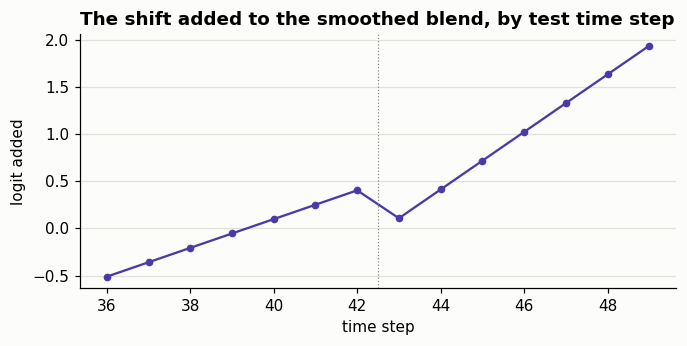

step,36,37,38,39,40,41,...,44,45,46,47,48,49
rows,1708.000,498.000,756.000,1183.000,1211.000,1132.000,...,1591.000,1221.000,712.000,846.000,471.000,476.000
logit shift,-0.511,-0.359,-0.206,-0.054,0.098,0.251,...,0.412,0.717,1.021,1.326,1.631,1.935


In [16]:
step = test.time_step.to_numpy()
early = ~late

# straight-line shift: the row-weighted least-squares line through a step function (0 on steps 43-44, +1.4 on 45-49), and half its slope before step 43
mirror_step = np.where(step >= 45, 1.4, 0.0)
level, centre = mirror_step[late].mean(), step[late].astype(float).mean()
slope = ((step[late] - centre) * (mirror_step[late] - level)).sum() / ((step[late] - centre) ** 2).sum()
centre_early = step[early].astype(float).mean()
ramp_shift = np.where(late, level + slope * (step - centre), slope / 2 * (step - centre_early))
print(f"steps 43-49: {level:.3f} + {slope:.3f} * (step - {centre:.2f});  steps 36-42: {slope / 2:.3f} * (step - {centre_early:.2f}) (mean zero)")

by_step = pd.DataFrame({"rows": [int((step == s).sum()) for s in range(36, 50)],
                        "logit shift": [ramp_shift[step == s][0] for s in range(36, 50)]}, index=pd.Index(range(36, 50), name="step"))
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_step.index, by_step["logit shift"], color=ACCENT, marker="o", markersize=4)
ax.axvline(42.5, color=MUTED, linewidth=0.8, linestyle=":")
ax.set(xlabel="time step", ylabel="logit added")
ax.set_title("The shift added to the smoothed blend, by test time step")
plt.show()
by_step.T.round(3)

**Self-training.** The test rows are unlabelled, but the model's most confident rows are usually right. Each round takes the current ordering, labels the highest-scored rows of each block illicit and the lowest-scored rows licit, adds those test rows to the labelled train rows and refits the supervised model; the PU model, smoother and shift stay as they are. A row is never scored by a model that saw its own pseudo-label or a neighbour's: the test rows are split into 5 folds by connected component of the hub-free graph, and each fold is scored by a model fitted on the other folds' pseudo-labels.

- **Round 1** labels from the ramp file (late-filter models plus the shift that grows with the step): in steps 43-49 the top 1% of rows illicit (67, the count the base model expects), in 36-42 every row with a positive score (588), and the bottom 60% of each block licit.
- **Round 2** uses the same rules on round 1's ordering.
- **Final round ("wide")** labels from round 2's ordering but more rows: the top 2% of steps 43-49 and the top 9% of steps 36-42 illicit, the bottom 80% licit. This is the top submission.

A fourth round (round 2's rules once more) scored lower on the leaderboard, so I stopped.

In [17]:
late_self_cols, early_self_cols = LATE_SEL + COUNT_COLS + STRUCT_COLS, SELECTED + COUNT_COLS + STRUCT_COLS
core_ramp = core_late_filter     # the smoothed blend before self-training; every step keeps its sorted scores from here on


def requantile(core_new, steps):
    """Rows of each step, ordered by core_new, take that step's sorted scores from core_ramp; other steps are left as they were."""
    out = core_ramp.copy()
    for s in steps:
        i = np.where(step == s)[0]
        out[i[np.argsort(core_new[i], kind="stable")]] = np.sort(core_ramp[i])
    return out


def pseudo_labels(core, n_illicit, licit_share):
    """1 for the n_illicit highest scores, 0 for the lowest licit_share of the rows, -1 (not used) for the middle."""
    order = np.argsort(-core)
    y = np.full(len(core), -1)
    y[order[:n_illicit]] = 1
    y[order[-int(round(licit_share * len(core))):]] = 0
    return y


def self_train(rows, cols, y_pseudo):
    """Supervised logit for the test rows in the mask `rows`: each fold is scored by a model fitted on labelled train + the pseudo-labelled rows of the other folds.
    The folds are connected components of the hub-free graph, so a row never meets its own pseudo-label or a neighbour's."""
    frame, scored = test_struct[rows], np.zeros(rows.sum())
    for fit_idx, held in GroupKFold(5).split(frame, groups=test_graph["component"][rows]):
        keep = fit_idx[y_pseudo[fit_idx] >= 0]
        X = pd.concat([labelled_struct[cols], frame.iloc[keep][cols]])
        y = np.r_[labelled_struct.label.to_numpy(), y_pseudo[keep]]
        scored[held] = fit_logits(lgbm, X, y, frame.iloc[held][cols], seeds=range(3))
    return scored


def self_training_round(core, late_rule, early_rule, label):
    """Pseudo-labels from `core` (rules are (illicit rows, licit share)), supervised model refitted on both blocks. Returns the new supervised logits."""
    y_late, y_early = pseudo_labels(core[late], *late_rule), pseudo_labels(core[early], *early_rule)
    print(f"{label}: steps 43-49 {int((y_late == 1).sum())} illicit / {int((y_late == 0).sum())} licit, "
          f"steps 36-42 {int((y_early == 1).sum())} illicit / {int((y_early == 0).sum())} licit", flush=True)
    supervised = mixed_supervised.copy()
    supervised[late], supervised[early] = self_train(late, late_self_cols, y_late), self_train(early, early_self_cols, y_early)
    return supervised


def reordered(supervised, steps):
    """core_ramp with the order inside `steps` taken from the refitted supervised model (PU model and smoother unchanged)."""
    return requantile(smooth_graph(0.7 * supervised + 0.3 * mixed_pu, test_graph, b=0.15), steps)


late_n = round(0.01 * late.sum())

round_1 = self_training_round(core_ramp, (late_n, 0.60), (int((core_ramp[early] > 0).sum()), 0.60), "round 1")
core_round_1 = reordered(round_1, range(36, 50))

round_2 = self_training_round(core_round_1, (late_n, 0.60), (int((core_round_1[early] > 0).sum()), 0.60), "round 2")
core_round_2 = reordered(round_2, range(36, 50))

wide_supervised = self_training_round(core_round_2, (round(0.02 * late.sum()), 0.80), (round(0.09 * early.sum()), 0.80), "wide labels")

round 1: steps 43-49 67 illicit / 4012 licit, steps 36-42 588 illicit / 5185 licit


round 2: steps 43-49 67 illicit / 4012 licit, steps 36-42 588 illicit / 5185 licit


wide labels: steps 43-49 134 illicit / 5350 licit, steps 36-42 778 illicit / 6914 licit


**Inference for the top submission.** The final blend is 0.7 × the self-trained supervised logits + 0.3 × the PU logits (late-filter columns on steps 43-49), smoothed over the test graph, re-scored step by step and shifted. Nothing is refitted in the next cell.

In [18]:
final_blend = 0.7 * wide_supervised + 0.3 * mixed_pu
final_core = requantile(smooth_graph(final_blend, test_graph, b=0.15), range(36, 50))
final_logit = final_core + ramp_shift
final_pred = expit(final_logit)

name = "selftrain_wide_3649_stepquantile"
print(f"supervised columns: {len(late_self_cols)} on steps 43-49 ({len(LATE_SEL)} drift-filtered + {len(COUNT_COLS)} neighbour counts + {len(STRUCT_COLS)} structural), "
      f"{len(early_self_cols)} on steps 36-42 ({len(SELECTED)} + {len(COUNT_COLS)} + {len(STRUCT_COLS)})")
print(f"{len(final_pred)} rows scored, predictions from {final_pred.min():.4f} to {final_pred.max():.4f}")
top = np.argsort(-final_logit)[:test_illicit]      # as many rows as the public totals imply are illicit
print(f"the {test_illicit} highest-scored rows: {int(late[top].sum())} in steps 43-49, {int((~late[top]).sum())} in steps 36-42")
note = compare_with_disk(final_pred, name)
print(f"\nwrote {write_submission(final_pred, name)}  ({note})")

supervised columns: 108 on steps 43-49 (97 drift-filtered + 3 neighbour counts + 8 structural), 108 on steps 36-42 (97 + 3 + 8)
15329 rows scored, predictions from 0.0000 to 0.9996
the 901 highest-scored rows: 218 in steps 43-49, 683 in steps 36-42

wrote submissions/selftrain_wide_3649_stepquantile.csv  (max difference from the file already on disk: 1.1e-16)


In [19]:
# last check on both files as written: shape, key and range, and how alike the two rankings are
for name in ("robust_struct_pu_refined", "selftrain_wide_3649_stepquantile"):
    out = pd.read_csv(SUBMISSIONS / f"{name}.csv")
    print(f"{name}: {out.shape}, columns {list(out.columns)}, index matches sample: {out['index'].equals(sample['index'])}, "
          f"target in [0, 1]: {bool(out.target.between(0, 1).all())}")
print(f"\nrank correlation between the two files: {pd.Series(robust_pred).corr(pd.Series(final_pred), method='spearman'):.4f}")

robust_struct_pu_refined: (15329, 2), columns ['index', 'target'], index matches sample: True, target in [0, 1]: True
selftrain_wide_3649_stepquantile: (15329, 2), columns ['index', 'target'], index matches sample: True, target in [0, 1]: True

rank correlation between the two files: 0.9198


## 9. Evidence from the leaderboard

Scores below were read off Kaggle (3 submissions a day) while the competition was open. *Recorded, not recomputed.* The public score covers 30% of test, the private score the other 70%.

**The path to the top file**, one change at a time (the public AUC of the file after each change):

| file | change | public AUC |
| --- | --- | --- |
| `lgbm_97_features` | LightGBM on the 97 selected features | 0.94458 |
| `lgbm_smooth_mean025` | + smoothing over test neighbours | 0.94653 |
| `lgbm_nbcounts_propagate` | + neighbour counts, 10-round propagation | 0.94790 |
| `robust_struct_pu_refined` (**second pick**, model A) | + structure features, PU model, refined smoother | 0.95031 |
| `maxscore_struct_pu30_late07` | PU weight 0.3, flat +0.7 logit on steps 43-49 | 0.95270 |
| `late_filter_4349_shift07` | + separate drift filter and models for steps 43-49 | 0.95365 |
| `late_mirror_4549_14_rest0` | shift 0 on steps 43-44, +1.4 on 45-49 | 0.95420 |
| `late_slope_lsq_of_mirror` | line instead of step function | 0.95543 |
| `early_ramp_3642_k015` | + half-slope line on steps 36-42 | 0.95597 |
| `selftrain_4349_stepquantile` | + self-training round 1, steps 43-49 | 0.95719 |
| `selftrain_3642_stepquantile` | + round 1, steps 36-42 | 0.95772 |
| `selftrain_r2_3649_stepquantile` | + round 2 | 0.95850 |
| `selftrain_wide_3649_stepquantile` (**top pick**, model B) | final round with wider pseudo-labels | 0.95832 (private **0.95986**) |

**Changes that lost or tied** (public AUC, against the file in brackets):

| change | public AUC | vs reference |
| --- | --- | --- |
| rank blend with aggregated-only model, 50% / 60% (validation had said +0.02) | 0.92153 / 0.91269 | against `lgbm_97_features`: -0.023 / -0.032 |
| shallow-tree blend, then smoothing | 0.94380 | against `lgbm_smooth_mean025`: -0.0027 |
| late rows shifted by -1.5 / +1.5 logit / count-matched +2.12 (on the first model) | 0.93738 / 0.94424 / 0.94184 | against `lgbm_97_features`: -0.007 / 0 / -0.003 |
| shift on steps 43-49: 0 / +0.7 / +1.0 (stack with PU weight 0.3) | 0.95031 / 0.95270 / 0.95241 | peak near +0.7 |
| step function reversed (+1.4 on 43-44, 0 on 45-49) | 0.94829 | against the flat +0.7 file: -0.0044 |
| line slope 0.45 / 0.18 instead of 0.305 | 0.95514 / 0.95518 | against 0.95543: -0.0003 |
| early slope 0.30 instead of 0.15 | 0.95580 | against 0.95597: -0.0002 |
| whole late block raised by 0.22 logit | 0.95549 | against 0.95597: -0.0005 |
| separate drift filter for steps 46-49 | 0.95596 | against 0.95597: tie |
| self-training round 3 (same rules as round 2) | 0.95806 | against 0.95850: -0.0004 |
| wider pseudo-labels (the top pick) | 0.95832 | against 0.95850: -0.0002 |

The shift levers (slope, mean, early slope, join between the blocks) are each within about 0.0003 of their peak, and self-training has plateaued: round 3 and the wider labels both scored slightly below round 2, within noise.

**How much of this is noise?** I simulated the public split: labels drawn from each pair of files' mean score (901 illicit rows, a score slope fitted so the best file scores about 0.958), public = a random 30% of test, private = the rest, 500 draws. The sd of (public gain - private gain) says how far a public gain can sit from the gain on the private 70% by chance. Sampling noise only; it does not include the selection effect of keeping the best of the many files I submitted.

| change | public gain | sd of public - private gain | gain in sd units |
| --- | --- | --- | --- |
| self-training, steps 43-49 | +0.00122 | 0.00076 | 1.6 |
| self-training, steps 36-42 | +0.00053 | 0.00054 | 1.0 |
| self-training round 2 | +0.00078 | 0.00042 | 1.9 |
| wider labels (instead of round 2) | -0.00018 | 0.00094 | -0.2 |
| round 3 (instead of round 2) | -0.00044 | 0.00040 | -1.1 |
| model A -> shift, line and filter (`early_ramp_3642_k015`) | +0.00566 | 0.00229 | 2.5 |
| model A -> top pick | +0.00801 | 0.00290 | 2.8 |

Reading: the move from model A to the shifted, filtered models is about 2.5 sd of the public sampling noise, so I believe it is real; the individual self-training rounds are each 1-2 sd and could be partly public-subset luck. The top pick scored 0.95986 on the private 70%, +0.0015 above its public score, which is 0.2 sd of the simulated public-private gap, so there is no sign that the public score was overfitted. Simulated for the top file alone: public AUC sd 0.0066, private sd 0.0043.